In [1]:
# --- Install required libraries ---
!pip install torch torchvision matplotlib medmnist pytorch-fid --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 87.2/87.2 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 54.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 33.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 78.4 MB/s eta 0:00:00


In [2]:
import os
import math
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader, ConcatDataset
import torch.nn.functional as Fnn

import torchvision.models as models
import torchvision.transforms as transforms
import torchvision.transforms.functional as F
from torchvision.utils import save_image, make_grid

import matplotlib.pyplot as plt
from tqdm import tqdm

import medmnist
from medmnist import INFO, Evaluator

from pytorch_fid import fid_score


In [3]:
print(f"MedMNIST v{medmnist.__version__} @ {medmnist.HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [4]:
data_flag = 'bloodmnist'
download = True
BATCH_SIZE = 128

info = INFO[data_flag]
task = info['task']
n_channels = info['n_channels']
n_classes = len(info['label'])

DataClass = getattr(medmnist, info['python_class'])

In [5]:

# preprocessing
data_transform = transforms.Compose([
    transforms.ToTensor(),
])

# Load all splits
train = DataClass(split='train', transform=data_transform, download=True)
val = DataClass(split='val', transform=data_transform, download=True)
test = DataClass(split='test', transform=data_transform, download=True)

# Combine them into a single dataset
full_dataset = ConcatDataset([train, val, test])
dataloader = DataLoader(full_dataset, batch_size=128, shuffle=True)

100%|██████████| 35.5M/35.5M [00:02<00:00, 12.1MB/s]


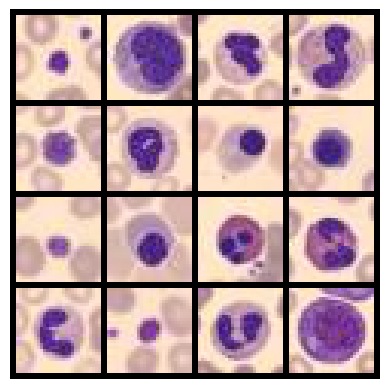

In [6]:
# visualization
# Get a few samples
samples = [full_dataset[i][0] for i in range(16)]  # assuming (image, label) tuples

# Make a grid
grid = make_grid(samples, nrow=4)

# Display
plt.imshow(F.to_pil_image(grid))
plt.axis('off')
plt.show()

## **Data Analysis**

In [7]:
# Analyze dataset length for each split
print(f"Train samples: {len(train)}")
print(f"Validation samples: {len(val)}")
print(f"Test samples: {len(test)}")
print(f"Total samples: {len(full_dataset)}")

Train samples: 11959
Validation samples: 1712
Test samples: 3421
Total samples: 17092


In [8]:
# Analyze image shape and data type for some samples
sample_image, _ = full_dataset[0]  # label is ignored here
print(f"Sample image shape (C, H, W): {sample_image.shape}")
print(f"Sample image data type: {sample_image.dtype}")
print(f"Pixel value range: min={sample_image.min().item()}, max={sample_image.max().item()}")

Sample image shape (C, H, W): torch.Size([3, 28, 28])
Sample image data type: torch.float32
Pixel value range: min=0.12941177189350128, max=1.0


In [9]:
# Check the distribution of image shapes in the dataset (should be consistent)
unique_shapes = set()
for i in range(len(full_dataset)):
    img, _ = full_dataset[i]
    unique_shapes.add(img.shape)
print(f"Unique image shapes in dataset: {unique_shapes}")

Unique image shapes in dataset: {torch.Size([3, 28, 28])}


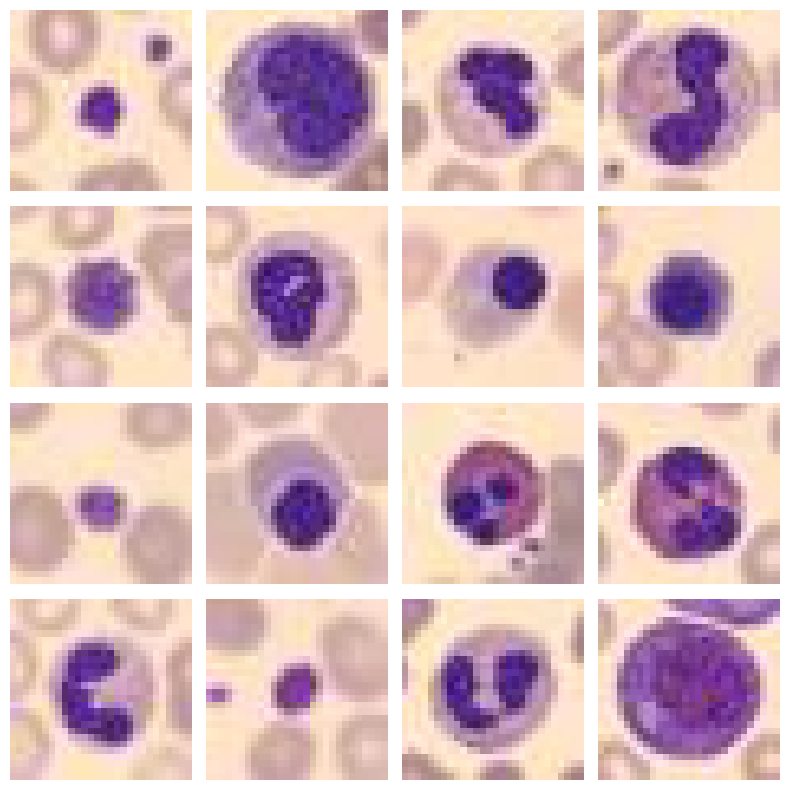

In [10]:

# Visualize a grid of sample images without labels
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for i, ax in enumerate(axes.flat):
    img, _ = full_dataset[i]
    # img shape: (channels, height, width) -> convert to (height, width, channels)
    img_np = img.permute(1, 2, 0).numpy()
    ax.imshow(img_np)
    ax.axis('off')
plt.tight_layout()
plt.show()


## **Train Variational Autoencoder (VAE)**

In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [12]:
# Define VAE model
class VAE(nn.Module):
    def __init__(self, image_channels=3, latent_dim=128):
        super().__init__()
        self.latent_dim = latent_dim

        # Encoder: 4 conv layers to reduce 28x28 to 2x2 feature maps
        self.encoder = nn.Sequential(
            nn.Conv2d(image_channels, 64, kernel_size=3, stride=2, padding=1),  # 3x28x28 -> 64x14x14
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 128, 3, 2, 1),  # 64x14x14 -> 128x7x7
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 256, 3, 2, 1), # 128x7x7 -> 256x4x4
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.Conv2d(256, 512, 3, 2, 1), # 256x4x4 -> 512x2x2
            nn.BatchNorm2d(512),
            nn.ReLU(),

            nn.Flatten(),                 # 512*2*2=2048
        )

        self.fc_mu = nn.Linear(512*2*2, latent_dim)
        self.fc_logvar = nn.Linear(512*2*2, latent_dim)

        # Decoder input fully connected layer
        self.decoder_input = nn.Linear(latent_dim, 512*2*2)

        # Decoder: ConvTranspose to upsample back to 28x28
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(512, 256, 3, 2, 1, output_padding=1),  # 512x2x2 -> 256x4x4
            nn.BatchNorm2d(256),
            nn.ReLU(),

            nn.ConvTranspose2d(256, 128, 3, 2, 1, output_padding=1),  # 256x4x4 -> 128x8x8
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.ConvTranspose2d(128, 64, 4, 2, 1),                    # 128x8x8 -> 64x16x16
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.ConvTranspose2d(64, image_channels, 4, 2, 1),          # 64x16x16 -> 3x32x32 (slightly larger)
            nn.Sigmoid(),
        )

    def encode(self, x):
        x_enc = self.encoder(x)
        mu = self.fc_mu(x_enc)
        logvar = self.fc_logvar(x_enc)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        x = self.decoder_input(z)
        x = x.view(-1, 512, 2, 2)
        x_recon = self.decoder(x)
        # Crop output to 28x28 (from 32x32)
        x_recon = x_recon[:, :, :28, :28]
        return x_recon

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_recon = self.decode(z)
        return x_recon, mu, logvar

In [13]:
def vae_loss(recon_x, x, mu, logvar):
    recon_loss = Fnn.mse_loss(recon_x, x, reduction='sum')
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl_loss

In [14]:
# Model, optimizer, and hyperparams
vae = VAE(image_channels=3, latent_dim=64).to(device)
optimizer = optim.Adam(vae.parameters(), lr=1e-3)
num_epochs = 1000

In [15]:
train_losses = []

print("Starting training...")
for epoch in range(num_epochs):
    vae.train()
    running_loss = 0
    loop = tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}")
    for images, _ in loop:
        images = images.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = vae(images)
        loss = vae_loss(recon, images, mu, logvar)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        loop.set_postfix(loss=running_loss / ((loop.n + 1) * images.size(0)))

    epoch_loss = running_loss / len(dataloader.dataset)
    train_losses.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.4f}")

Starting training...


Epoch 1/1000: 100%|██████████| 134/134 [00:08<00:00, 15.78it/s, loss=89.1]


Epoch [1/1000] Train Loss: 47.1482


Epoch 2/1000: 100%|██████████| 134/134 [00:05<00:00, 23.79it/s, loss=62.3]


Epoch [2/1000] Train Loss: 32.9444


...

Epoch [998/1000] Train Loss: 26.8840


Epoch 999/1000: 100%|██████████| 134/134 [00:06<00:00, 19.70it/s, loss=51.1]


Epoch [999/1000] Train Loss: 26.8579


Epoch 1000/1000: 100%|██████████| 134/134 [00:06<00:00, 20.57it/s, loss=50.8]

Epoch [1000/1000] Train Loss: 26.9009


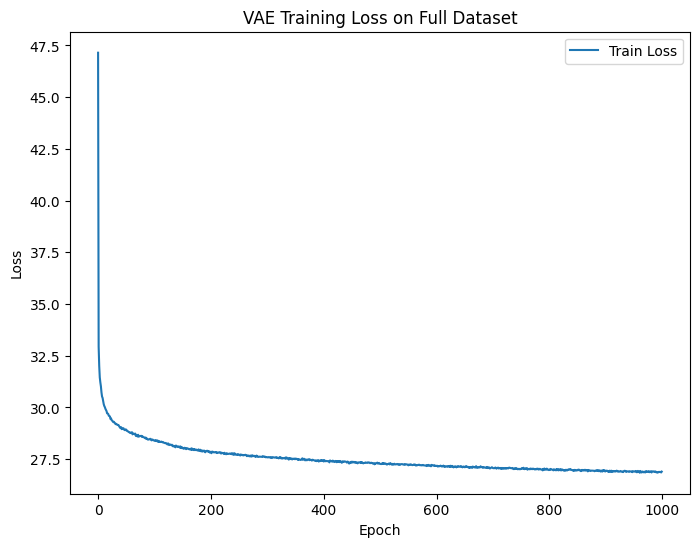

In [16]:
# Plot training loss
plt.figure(figsize=(8,6))
plt.plot(train_losses, label='Train Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('VAE Training Loss on Full Dataset')
plt.legend()
plt.show()

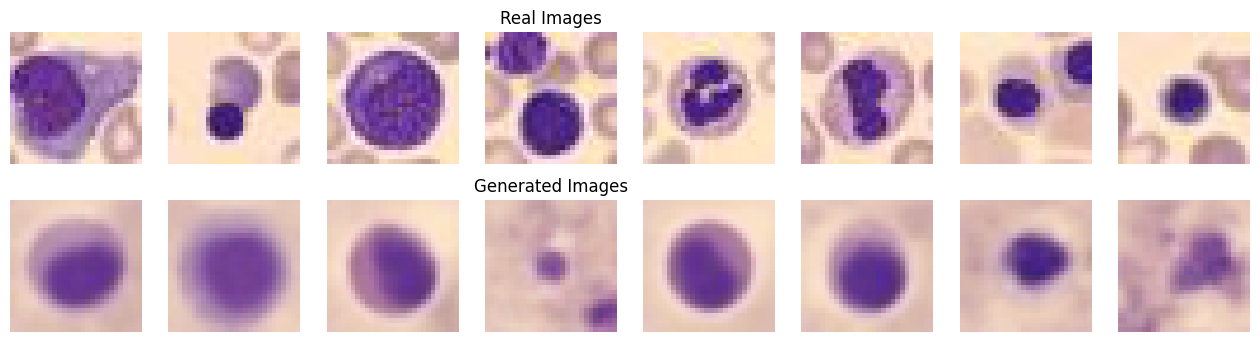

In [17]:
# Visualize real vs generated images side-by-side
vae.eval()
with torch.no_grad():
    real_samples, _ = next(iter(dataloader))
    real_samples = real_samples[:8].to(device)
    z = torch.randn(8, vae.latent_dim).to(device)
    generated_samples = vae.decode(z).clamp(0, 1)

    fig, axes = plt.subplots(2, 8, figsize=(16, 4))
    for i in range(8):
        ax = axes[0, i]
        img = real_samples[i].cpu().permute(1, 2, 0).numpy()
        ax.imshow(img)
        ax.axis('off')
        if i == 3:
            ax.set_title("Real Images")

        ax = axes[1, i]
        gen_img = generated_samples[i].cpu().permute(1, 2, 0).numpy()
        ax.imshow(gen_img)
        ax.axis('off')
        if i == 3:
            ax.set_title("Generated Images")
    plt.show()

In [18]:
# Calculate FID on 10,000 samples

real_dir = '/tmp/real_samples'
gen_dir = '/tmp/generated_samples'
os.makedirs(real_dir, exist_ok=True)
os.makedirs(gen_dir, exist_ok=True)

print("Saving 10,000 real images...")
for i in tqdm(range(10000)):
    img, _ = full_dataset[i]
    save_image(img, os.path.join(real_dir, f"real_{i}.png"))

print("Saving 10,000 generated images...")
batch_size = 128
num_batches = 10000 // batch_size
for i in tqdm(range(num_batches)):
    z = torch.randn(batch_size, vae.latent_dim).to(device)
    gen_imgs = vae.decode(z).clamp(0, 1)
    for j in range(batch_size):
        idx = i * batch_size + j
        if idx >= 10000:
            break
        save_image(gen_imgs[j], os.path.join(gen_dir, f"gen_{idx}.png"))

print("Calculating FID...")
fid_value = fid_score.calculate_fid_given_paths([real_dir, gen_dir], batch_size=50, device=device, dims=2048)
print(f"FID score: {fid_value:.4f}")

Saving 10,000 real images...


100%|██████████| 10000/10000 [00:07<00:00, 1414.66it/s]


Saving 10,000 generated images...


100%|██████████| 78/78 [00:08<00:00,  9.53it/s]


Calculating FID...


Downloading: "https://github.com/mseitzer/pytorch-fid/releases/download/fid_weights/pt_inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/pt_inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 124MB/s]
100%|██████████| 200/200 [00:40<00:00,  4.99it/s]


FID score: 172.7026
